# 06 - Exploratory Data Analysis: DermaMNIST

Second subset in the project. Unlike PneumoniaMNIST (grayscale, binary), DermaMNIST is **RGB** and **multi-class** (7 skin lesion types), and is known to be considerably more imbalanced. This EDA checks those properties before training, the same way the PneumoniaMNIST EDA shaped the training/evaluation choices for phase 1.

In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_dataset, get_spec, compute_normalization_stats
from src.utils import set_seed

set_seed(42)
FLAG = "dermamnist"
SIZE = 28


## 1. Dataset specification

In [3]:
spec = get_spec(FLAG)
print(spec)
print(f"\nTask type: {spec.task} -> this is MULTI-CLASS, unlike PneumoniaMNIST's binary task.")
print(f"n_channels: {spec.n_channels} -> RGB, unlike PneumoniaMNIST's grayscale.")

DatasetSpec(flag='dermamnist', task='multi-class', n_channels=3, n_classes=7, labels={'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'})

Task type: multi-class -> this is MULTI-CLASS, unlike PneumoniaMNIST's binary task.
n_channels: 3 -> RGB, unlike PneumoniaMNIST's grayscale.


## 2. Loading the splits

In [4]:
splits = {s: get_dataset(FLAG, s, size=SIZE, root="../data") for s in ["train", "val", "test"]}
for name, ds in splits.items():
    print(f"{name:>5}: {len(ds):>5} images | image array shape: {ds.imgs.shape}")

100%|██████████| 19.7M/19.7M [00:49<00:00, 401kB/s] 


train:  7007 images | image array shape: (7007, 28, 28, 3)
  val:  1003 images | image array shape: (1003, 28, 28, 3)
 test:  2005 images | image array shape: (2005, 28, 28, 3)


## 3. Class distribution

With 7 classes instead of 2, imbalance is usually much more severe: one or two common lesion types can dominate the dataset while rare types have very few examples.

split,train,val,test,train_proportion
class,,,,
melanocytic nevi,4693,671,1341,0.6698
melanoma,779,111,223,0.1112
benign keratosis-like lesions,769,110,220,0.1097
basal cell carcinoma,359,52,103,0.0512
actinic keratoses and intraepithelial carcinoma,228,33,66,0.0325
vascular lesions,99,14,29,0.0141
dermatofibroma,80,12,23,0.0114


C:\Users\Micro\AppData\Local\Temp\ipykernel_13680\3896962458.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


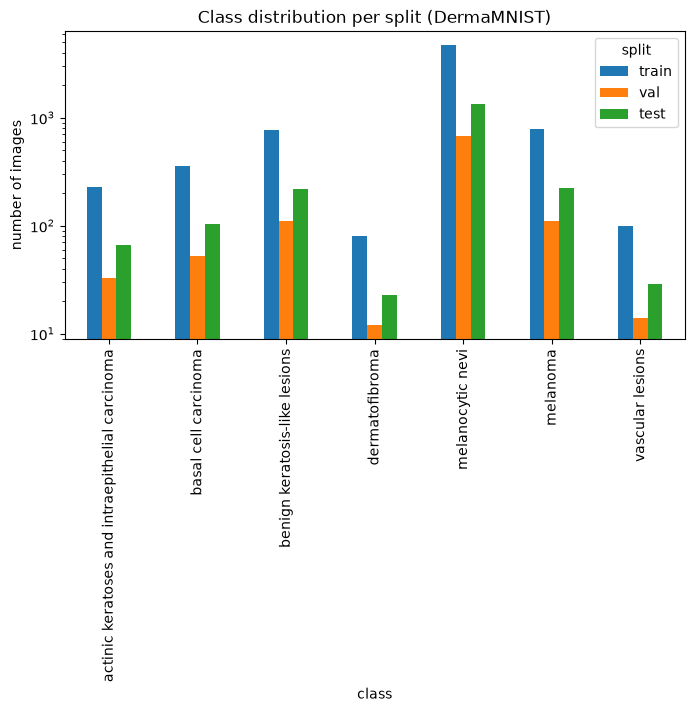

In [5]:
rows = []
for name, ds in splits.items():
    labels = ds.labels.flatten()
    for cls, count in zip(*np.unique(labels, return_counts=True)):
        rows.append({"split": name, "class": spec.labels[str(cls)], "n": count})
df = pd.DataFrame(rows)
df["proportion"] = df.groupby("split")["n"].transform(lambda x: x / x.sum())
pivot = df.pivot(index="class", columns="split", values="n")[["train", "val", "test"]]
pivot["train_proportion"] = (pivot["train"] / pivot["train"].sum()).round(4)
display(pivot.sort_values("train", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
pivot[["train", "val", "test"]].plot(kind="bar", ax=ax)
ax.set_ylabel("number of images"); ax.set_title("Class distribution per split (DermaMNIST)")
ax.set_yscale("log")  # log scale: class sizes likely differ by orders of magnitude
plt.tight_layout(); plt.show()

## 4. Majority-class baseline

The reference every model must beat, same role as in the PneumoniaMNIST EDA.

In [6]:
from src.metrics import majority_class_baseline

for name, ds in splits.items():
    baseline = majority_class_baseline(ds.labels.flatten())
    print(f"{name:>5}: always predicting the majority class gets {baseline:.4f} accuracy")

train: always predicting the majority class gets 0.6698 accuracy
  val: always predicting the majority class gets 0.6690 accuracy
 test: always predicting the majority class gets 0.6688 accuracy


## 5. Visual examples

One example per class, if available.

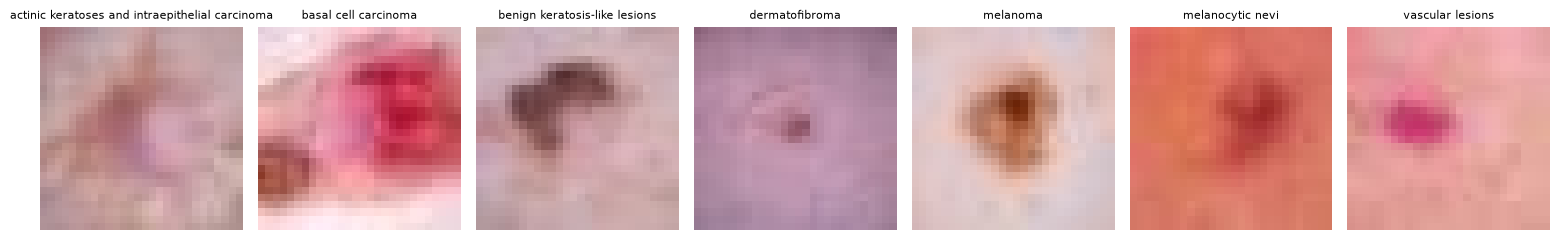

In [7]:
n_classes = spec.n_classes
fig, axes = plt.subplots(1, n_classes, figsize=(2.2 * n_classes, 2.6))
train = splits["train"]
labels_flat = train.labels.flatten()
for i in range(n_classes):
    idx = np.where(labels_flat == i)[0]
    ax = axes[i]
    if len(idx) > 0:
        ax.imshow(train.imgs[idx[0]])
    ax.axis("off")
    ax.set_title(spec.labels[str(i)], fontsize=8)
plt.tight_layout(); plt.show()

## 6. Pixel statistics (per channel)

RGB images have three channels, so normalization needs a mean/std per channel, not a single global number as in PneumoniaMNIST. `compute_normalization_stats` (in `src/data.py`) already handles this automatically — this cell just inspects what it computes.

In [8]:
mean, std = compute_normalization_stats(FLAG, size=SIZE, root="../data")
print("Per-channel mean (R, G, B):", [round(m, 4) for m in mean])
print("Per-channel std  (R, G, B):", [round(s, 4) for s in std])

Per-channel mean (R, G, B): [0.7636, 0.5372, 0.5614]
Per-channel std  (R, G, B): [0.1362, 0.154, 0.1687]


## 7. Observations

DermaMNIST is substantially more imbalanced than PneumoniaMNIST: the
majority class (melanocytic nevi) has ~59x more training examples than the
rarest class (dermatofibroma, 80 images), compared to a ~3x ratio in
PneumoniaMNIST. With 7 classes instead of 2, macro-averaged metrics
(balanced accuracy, F1) will be much more sensitive to performance on the
rare classes, so a high accuracy could still hide very poor performance on
dermatofibroma or vascular lesions.

Unlike PneumoniaMNIST, the majority-class baseline is stable across splits
(~0.669 in train, val and test), so validation metrics should be a more
reliable proxy for test performance here than they were in phase 1.

Visually, lesion types look fairly similar at 28x28 resolution — mostly
pink/brown roundish patches — suggesting the classification task is
genuinely harder than PneumoniaMNIST, independent of the data imbalance.
Given the severity of the imbalance, per-class results (not just macro
averages) will be important to inspect once models are trained.